# Logistic Regression 

Objective: Build a logistic regression classifier to recognize cats. 

**You will learn to:**
- Build the general architecture of a learning algorithm, including:
    - Initializing parameters
    - Calculating the cost function and its gradient
    - Using an optimization algorithm (gradient descent) 
- Gather all three functions above into a main model function, in the right order.

## 1 - Packages ##

First, let's run the cell below to import all the packages that are needed during this exercise. 
- [numpy](www.numpy.org) is the fundamental package for scientific computing with Python.
- [h5py](http://www.h5py.org) is a common package to interact with a dataset that is stored on an H5 file.
- [matplotlib](http://matplotlib.org) is a famous library to plot graphs in Python.
- [PIL](http://www.pythonware.com/products/pil/) and [scipy](https://www.scipy.org/) are used here to test your model with your own picture at the end.

In [64]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
import scipy
from PIL import Image
from scipy import ndimage

## 2 - Overview of the Problem set ##

**Problem Statement**: You are given a dataset ("data.h5") containing:
   - a training set of m_train images labeled as cat (y=1) or non-cat (y=0)
   - a test set of m_test images labeled as cat or non-cat
   - each image is of shape (num_px, num_px, 3) where 3 is for the 3 channels (RGB). Thus, each image is square (height = num_px) and (width = num_px).

The objective of the exercice is to build a simple algorithm that can correctly classify pictures as "cats" or "non-cats".

Let's get more familiar with the dataset. Load the data by running the following code.

In [65]:
# Loading the data (cat/non-cat)

train_dataset = h5py.File('train_catvnoncat.h5', "r")
train_set_x_orig = np.array(train_dataset["train_set_x"][:]) # The train set features
train_set_y_orig = np.array(train_dataset["train_set_y"][:]) # The train set labels

test_dataset = h5py.File('test_catvnoncat.h5', "r")
test_set_x_orig = np.array(test_dataset["test_set_x"][:]) # The test set features
test_set_y_orig = np.array(test_dataset["test_set_y"][:]) # The test set labels

classes = np.array(test_dataset["list_classes"][:]) # the list of classes
    
train_set_y = train_set_y_orig.reshape((1, train_set_y_orig.shape[0]))
test_set_y = test_set_y_orig.reshape((1, test_set_y_orig.shape[0]))  

We added "_orig" at the end of image datasets (train and test) because we are going to preprocess them. After preprocessing, we will end up with train_set_x and test_set_x (the labels train_set_y and test_set_y do not need any preprocessing).

Each line of your train_set_x_orig and test_set_x_orig is an array representing an image. You can visualize an example by running the following code. Feel free also to change the `index` value and re-run to see other images. 

y = [0], it's a 'non-cat' picture.


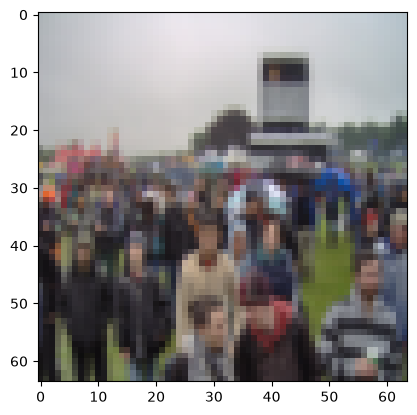

In [66]:
# Example of a picture
index = 100
plt.imshow(train_set_x_orig[index])
print ("y = " + str(train_set_y[:, index]) + ", it's a '" + classes[np.squeeze(train_set_y[:, index])].decode("utf-8") +  "' picture.")

Many software bugs in deep learning come from having matrix/vector dimensions that do not fit. If you can keep your matrix/vector dimensions straight you will go a long way toward eliminating many bugs. 

### TO DO
Find the values for:
   - m_train (number of training examples)
   - m_test (number of test examples)
   - num_px (= height = width of a training image)
Remember that `train_set_x_orig` is a numpy-array of shape (m_train, num_px, num_px, 3). For instance, you can access `m_train` by writing `train_set_x_orig.shape[0]`.

In [67]:
m_train = train_set_x_orig.shape[0]  # COMPLETE THIS LINE
m_test = test_set_x_orig.shape[0]   # COMPLETE THIS LINE
num_px_height = train_set_x_orig.shape[1]  # COMPLETE THIS LINE
num_px_width = train_set_x_orig.shape[2]  # COMPLETE THIS LINE

print ("Number of training examples: m_train = " + str(m_train))
print ("Number of testing examples: m_test = " + str(m_test))
print ("Height/Width of each image: num_px = " + str(num_px_height) + " x " + str(num_px_width))
print ("Each image is of size: (" + str(num_px_height) + ", " + str(num_px_width) + ", 3)")
print ("train_set_x shape: " + str(train_set_x_orig.shape))
print ("train_set_y shape: " + str(train_set_y.shape))
print ("test_set_x shape: " + str(test_set_x_orig.shape))
print ("test_set_y shape: " + str(test_set_y.shape))

Number of training examples: m_train = 209
Number of testing examples: m_test = 50
Height/Width of each image: num_px = 64 x 64
Each image is of size: (64, 64, 3)
train_set_x shape: (209, 64, 64, 3)
train_set_y shape: (1, 209)
test_set_x shape: (50, 64, 64, 3)
test_set_y shape: (1, 50)


### Questions: ###

- Are these informations about the data set (train and test) suffient?
- Should study and extract other relevant information about the data set?
- Explain and, if needed, complete the code and analyze the extracted informations?

For convenience, you should now reshape images of shape (num_px, num_px, 3) in a numpy-array of shape (num_px $*$ num_px $*$ 3, 1). After this, our training (and test) dataset is a numpy-array where each column represents a flattened image. There should be m_train (respectively m_test) columns.

### TO DO
Reshape the training and test data sets so that images of size (num_px, num_px, 3) are flattened into single vectors of shape (num\_px $*$ num\_px $*$ 3, 1).

A trick when you want to flatten a matrix X of shape (a,b,c,d) to a matrix X_flatten of shape (b$*$c$*$d, a) is to use: 
```python
X_flatten = X.reshape(X.shape[0], -1).T      # X.T is the transpose of X
```

In [68]:
# Reshape the training and test examples
train_set_x_flatten = train_set_x_orig.reshape(train_set_x_orig.shape[0], -1).T  # COMPLETE THIS LINE
test_set_x_flatten = test_set_x_orig.reshape(test_set_x_orig.shape[0], -1).T  # COMPLETE THIS LINE

print ("train_set_x_flatten shape: " + str(train_set_x_flatten.shape))
print ("train_set_y shape: " + str(train_set_y.shape))
print ("test_set_x_flatten shape: " + str(test_set_x_flatten.shape))
print ("test_set_y shape: " + str(test_set_y.shape))
print ("sanity check after reshaping: " + str(train_set_x_flatten[0:5,0]))


train_set_x_flatten shape: (12288, 209)
train_set_y shape: (1, 209)
test_set_x_flatten shape: (12288, 50)
test_set_y shape: (1, 50)
sanity check after reshaping: [17 31 56 22 33]


**Expected Output**: 

<table style="width:35%">
  <tr>
    <td>**train_set_x_flatten shape**</td>
    <td> (12288, 209)</td> 
  </tr>
  <tr>
    <td>**train_set_y shape**</td>
    <td>(1, 209)</td> 
  </tr>
  <tr>
    <td>**test_set_x_flatten shape**</td>
    <td>(12288, 50)</td> 
  </tr>
  <tr>
    <td>**test_set_y shape**</td>
    <td>(1, 50)</td> 
  </tr>
  <tr>
  <td>**sanity check after reshaping**</td>
  <td>[17 31 56 22 33]</td> 
  </tr>
</table>

To represent color images, the red, green and blue channels (RGB) must be specified for each pixel, and so the pixel value is actually a vector of three numbers ranging from 0 to 255.

One common preprocessing step in machine learning is to center and standardize your dataset, meaning that you substract the mean of the whole numpy array from each example, and then divide each example by the standard deviation of the whole numpy array. But for picture datasets, it is simpler and more convenient and works almost as well to just divide every row of the dataset by 255 (the maximum value of a pixel channel).

<!-- During the training of your model, you're going to multiply weights and add biases to some initial inputs in order to observe neuron activations. Then you backpropogate with the gradients to train the model. But, it is extremely important for each feature to have a similar range such that our gradients don't explode. You will see that more in detail later in the lectures. !--> 

Let's standardize our dataset.

In [69]:
train_set_x = train_set_x_flatten / 255.  # COMPLETE THIS LINE
test_set_x = test_set_x_flatten / 255.  # COMPLETE THIS LINE
print ("sanity check after reshaping: " + str(train_set_x[0:5,0]))

sanity check after reshaping: [0.06666667 0.12156863 0.21960784 0.08627451 0.12941176]


<font color='blue'>
**What you need to remember:**

Common steps for pre-processing a new dataset are:
- Figure out the dimensions and shapes of the problem (m_train, m_test, num_px, ...)
- Reshape the datasets such that each example is now a vector of size (num_px \* num_px \* 3, 1)
- "Standardize" the data

## 3 - General Architecture of the learning algorithm ##

It's time to design a simple algorithm to distinguish cat images from non-cat images.

You will build a Logistic Regression, using a Neural Network. The following Figure explains why **Logistic Regression is actually a very simple Neural Network!**

<img src="LogReg.png" style="width:650px;height:400px;">

**Mathematical expression of the algorithm**:

For one example $x^{(i)}$:
$$z^{(i)} = w^T x^{(i)} + b$$
$$\hat{y}^{(i)} = a^{(i)} = \operatorname{sigmoid}(z^{(i)})$$
$$\mathcal{L}(a^{(i)}, y^{(i)}) = -y^{(i)}\log(a^{(i)}) - (1-y^{(i)})\log(1-a^{(i)})$$

The cost is then computed by summing over all training examples:
$$J = \frac{1}{m} \sum_{i=1}^m \mathcal{L}(a^{(i)}, y^{(i)})$$

**Key steps**:
In this exercise, you will carry out the following steps: 
- Initialize the parameters of the model
- Learn the parameters for the model by minimizing the cost  
- Use the learned parameters to make predictions (on the test set)
- Analyse the results and conclude

## 4 - Building the parts of our algorithm ## 

The main steps for building a Neural Network are:
1. Define the model structure (such as number of input features) 
2. Initialize the model's parameters
3. Loop:
    - Calculate current loss (forward propagation)
    - Calculate current gradient (backward propagation)
    - Update parameters (gradient descent)

We often build steps 1-3 separately and integrate them into one function that we call `model()`.

### 4.1 - Helper functions

#### TO DO 
Implement the function `sigmoid()`. As you've seen in the figure above, you need to compute $sigmoid( w^T x + b) = \frac{1}{1 + e^{-(w^T x + b)}}$ to make predictions. You can use np.exp().

In [70]:
def sigmoid(z):
    """
    Compute the sigmoid of z

    Arguments:
    z -- A scalar or numpy array of any size.

    Return:
    s -- sigmoid(z)
    """
    s = 1 / (1 + np.exp(-z))  # COMPLETE THIS LINE
    
    return s

In [71]:
print ("sigmoid([0, 2]) = " + str(sigmoid(np.array([0,2]))))

sigmoid([0, 2]) = [0.5        0.88079708]


**Expected Output**: 

<table>
  <tr>
    <td>**sigmoid([0, 2])**</td>
    <td> [ 0.5         0.88079708]</td> 
  </tr>
</table>

### 4.2 - Initializing parameters

#### TO DO
- Implement parameter initialization in the cell below. You have to initialize w as a vector of zeros. 

In [72]:
def initialize_with_zeros(dim):
    """
    This function creates a vector of zeros of shape (dim, 1) for w and initializes b to 0.
    
    Argument:
    dim -- size of the w vector we want (or number of parameters in this case)
    
    Returns:
    w -- initialized vector of shape (dim, 1)
    b -- initialized scalar (corresponds to the bias)
    """

    w = np.zeros((dim, 1))  # COMPLETE THIS LINE
    b = 0

    assert(w.shape == (dim, 1))
    assert(isinstance(b, float) or isinstance(b, int))
    
    return w, b

In [73]:
dim = 2
w , b = initialize_with_zeros(dim)
print ("w = " + str(w))
print ("b = " + str(b))

w = [[0.]
 [0.]]
b = 0


**Expected Output**: 


<table style="width:15%">
    <tr>
        <td>  ** w **  </td>
        <td> [[ 0.]
 [ 0.]] </td>
    </tr>
    <tr>
        <td>  ** b **  </td>
        <td> 0 </td>
    </tr>
</table>

For image inputs, w will be of shape (num_px $\times$ num_px $\times$ 3, 1).

### 4.3 - Forward and Backward propagation

Now that your parameters are initialized, you can do the "forward" and "backward" propagation steps for learning the parameters.

**TO DO:** Implement a function `propagate()` that computes the cost function and its gradient.

**Hints**:

Forward Propagation:
- You get X
- You compute $A = \sigma(w^T X + b) = (a^{(0)}, a^{(1)}, ..., a^{(m-1)}, a^{(m)})$
- You calculate the cost function: $J = -\frac{1}{m}\sum_{i=1}^{m}y^{(i)}\log(a^{(i)})+(1-y^{(i)})\log(1-a^{(i)})$

Here are the two formulas you will be using: 

$$\frac{\partial J}{\partial w} = \frac{1}{m}X(A-Y)^T$$
$$\frac{\partial J}{\partial b} = \frac{1}{m} \sum_{i=1}^m (a^{(i)}-y^{(i)})$$

In [74]:
def propagate(w, b, X, Y):
    """
    Implement the cost function and its gradient for the propagation explained above

    Arguments:
    w -- weights, a numpy array of size (num_px * num_px * 3, 1)
    b -- bias, a scalar
    X -- data of size (num_px * num_px * 3, number of examples)
    Y -- true "label" vector (containing 0 if non-cat, 1 if cat) of size (1, number of examples)

    Return:
    cost -- negative log-likelihood cost for logistic regression
    dw -- gradient of the loss with respect to w, thus same shape as w
    db -- gradient of the loss with respect to b, thus same shape as b
    
    Tips:
    - Write your code step by step for the propagation. np.log(), np.dot()
    """
    
    m = X.shape[1]
    
    # FORWARD PROPAGATION (FROM X TO COST)
    A = sigmoid(np.dot(w.T, X) + b)  # COMPLETE THIS LINE                                   # compute activation
    cost = -np.sum(Y * np.log(A) + (1 - Y) * np.log(1 - A)) / m  # COMPLETE THIS LINE    # compute cost
    
    # BACKWARD PROPAGATION (TO FIND GRAD)
    dw = (np.dot(X, (A - Y).T) / m)  # COMPLETE THIS LINE
    db = np.sum(A - Y) / m  # COMPLETE THIS LINE

    assert(dw.shape == w.shape)
    assert(db.dtype == float)
    cost = np.squeeze(cost)
    assert(cost.shape == ())
    
    grads = {"dw": dw,
             "db": db}
    return grads, cost

In [75]:
w, b, X, Y = np.array([[1.],[2.]]), 2., np.array([[1.,2.,-1.],[3.,4.,-3.2]]), np.array([[1,0,1]])
grads, cost = propagate(w, b, X, Y)

print ("grads dw = " + str(grads["dw"]))
print ("grdas db = " + str(grads["db"]))
print ("cost = " + str(cost))

grads dw = [[0.99845601]
 [2.39507239]]
grdas db = 0.001455578136784208
cost = 5.801545319394553


**Expected Output**:

<table style="width:50%">
    <tr>
        <td>  ** dw **  </td>
      <td> [[ 0.99845601]
     [ 2.39507239]]</td>
    </tr>
    <tr>
        <td>  ** db **  </td>
        <td> 0.00145557813678 </td>
    </tr>
    <tr>
        <td>  ** cost **  </td>
        <td> 5.801545319394553 </td>
    </tr>

</table>

### d) Optimization (Training)
- You have initialized your parameters.
- You are also able to compute a cost function and its gradient.
- Now, you want to update the parameters using gradient descent.

In [76]:
def optimize(w, b, X, Y, num_iterations, learning_rate, print_cost = False):
    """
    This function optimizes w and b by running a gradient descent algorithm
    
    Arguments:
    w -- weights, a numpy array of size (num_px * num_px * 3, 1)
    b -- bias, a scalar
    X -- data of shape (num_px * num_px * 3, number of examples)
    Y -- true "label" vector (containing 0 if non-cat, 1 if cat), of shape (1, number of examples)
    num_iterations -- number of iterations of the optimization loop
    learning_rate -- learning rate of the gradient descent update rule
    print_cost -- True to print the loss every 100 steps
    
    Returns:
    params -- dictionary containing the weights w and bias b
    grads -- dictionary containing the gradients of the weights and bias with respect to the cost function
    costs -- list of all the costs computed during the optimization, this will be used to plot the learning curve.
    
    Tips:
    You basically need to write down two steps and iterate through them:
        1) Calculate the cost and the gradient for the current parameters. Use propagate().
        2) Update the parameters using gradient descent rule for w and b.
    """
    
    costs = []
    
    for i in range(num_iterations):
        
        
        # Cost and gradient calculation (≈ 1-4 lines of code)
        grads, cost = propagate(w, b, X, Y)
        
        # Retrieve derivatives from grads
        dw = grads["dw"]
        db = grads["db"]
        
        # update rule 
        w = w - learning_rate * dw  # COMPLETE THIS LINE
        b = b - learning_rate * db  # COMPLETE THIS LINE
        
        # Record and orint the cost every 100 training examples
        if i % 100 == 0:
            costs.append(cost)
        
        if print_cost and i % 100 == 0:
            print ("Cost after iteration %i: %f" %(i, cost))
    
    params = {"w": w,
              "b": b}
    
    grads = {"dw": dw,
             "db": db}
    
    return params, grads, costs

The previous function will output the learned w and b. We are able to use w and b to predict the labels for a dataset X. Implement the `predict()` function. There is two steps to computing predictions:

1. Calculate $\hat{Y} = A = \sigma(w^T X + b)$

2. Convert the entries of a into 0 (if activation <= 0.5) or 1 (if activation > 0.5), stores the predictions in a vector `Y_prediction`. If you wish, you can use an `if`/`else` statement in a `for` loop (though there is also a way to vectorize this). 

In [77]:
# prediction

def predict(w, b, X):
    '''
    Predict whether the label is 0 or 1 using learned logistic regression parameters (w, b)
    
    Arguments:
    w -- weights, a numpy array of size (num_px * num_px * 3, 1)
    b -- bias, a scalar
    X -- data of size (num_px * num_px * 3, number of examples)
    
    Returns:
    Y_prediction -- a numpy array (vector) containing all predictions (0/1) for the examples in X
    '''
    
    m = X.shape[1]
    Y_prediction = np.zeros((1,m))
    w = w.reshape(X.shape[0], 1)
    
    # Compute vector "A" predicting the probabilities of a cat being present in the picture
    A = sigmoid(np.dot(w.T,X)+b)
    
    for i in range(A.shape[1]):
        
        # Convert probabilities A[0,i] to actual predictions p[0,i]
        Y_prediction = np.where(A > 0.5, 1.0, 0.0)
    
    assert(Y_prediction.shape == (1, m))
    
    return Y_prediction

<font color='blue'>
**What to remember:**
You've implemented several functions that:
- Initialize (w,b)
- Optimize the loss iteratively to learn parameters (w,b):
    - computing the cost and its gradient 
    - updating the parameters using gradient descent
- Use the learned (w,b) to predict the labels for a given set of examples

## 5 - Merge all functions into a model ##

You will now see how the overall model is structured by putting together all the building blocks (functions implemented in the previous parts) together, in the right order.

### TO DO 
Implement the model function (complete the missing lines). Use the following notation:
    - Y_prediction for your predictions on the test set
    - Y_prediction_train for your predictions on the train set
    - w, costs, grads for the outputs of optimize()

In [78]:
def model(X_train, Y_train, X_test, Y_test, num_iterations = 2000, learning_rate = 0.5, print_cost = False):
    """
    Builds the logistic regression model by calling the function you've implemented previously
    
    Arguments:
    X_train -- training set represented by a numpy array of shape (num_px * num_px * 3, m_train)
    Y_train -- training labels represented by a numpy array (vector) of shape (1, m_train)
    X_test -- test set represented by a numpy array of shape (num_px * num_px * 3, m_test)
    Y_test -- test labels represented by a numpy array (vector) of shape (1, m_test)
    num_iterations -- hyperparameter representing the number of iterations to optimize the parameters
    learning_rate -- hyperparameter representing the learning rate used in the update rule of optimize()
    print_cost -- Set to true to print the cost every 100 iterations
    
    Returns:
    d -- dictionary containing information about the model.
    """
    
    # initialize parameters with zeros (≈ 1 line of code)
    dim2 = len(X_train)
    w, b = initialize_with_zeros(dim2)  # COMPLETE THE LINE

    # Gradient descent (≈ 1 line of code)
    parameters, grads, costs = optimize(w, b, X_train, Y_train, num_iterations, learning_rate, print_cost)  # COMPLETE THE LINE
    
    # Retrieve parameters w and b from dictionary "parameters"
    w = parameters["w"]
    b = parameters["b"]
    
    # Predict test/train set examples 
    Y_prediction_test = predict(w, b, X_test)  # COMPLETE THE LINE
    Y_prediction_train = predict(w, b, X_train)  # COMPLETE THE LINE

    print(w)
    print(b)
    print("train accuracy: {} %".format(100 - np.mean(np.abs(Y_prediction_train - Y_train)) * 100))
    print("test accuracy: {} %".format(100 - np.mean(np.abs(Y_prediction_test - Y_test)) * 100))

    
    d = {"costs": costs,
         "Y_prediction_test": Y_prediction_test, 
         "Y_prediction_train" : Y_prediction_train, 
         "w" : w, 
         "b" : b,
         "learning_rate" : learning_rate,
         "num_iterations": num_iterations}
    
    return d

Run the following cell to train your model.

In [79]:
d = model(train_set_x, train_set_y, test_set_x, test_set_y, num_iterations = 2000, learning_rate = 0.005, print_cost = True)

Cost after iteration 0: 0.693147
Cost after iteration 100: 0.584508
Cost after iteration 200: 0.466949
Cost after iteration 300: 0.376007
Cost after iteration 400: 0.331463
Cost after iteration 500: 0.303273
Cost after iteration 600: 0.279880
Cost after iteration 700: 0.260042
Cost after iteration 800: 0.242941
Cost after iteration 900: 0.228004
Cost after iteration 1000: 0.214820
Cost after iteration 1100: 0.203078
Cost after iteration 1200: 0.192544
Cost after iteration 1300: 0.183033
Cost after iteration 1400: 0.174399
Cost after iteration 1500: 0.166521
Cost after iteration 1600: 0.159305
Cost after iteration 1700: 0.152667
Cost after iteration 1800: 0.146542
Cost after iteration 1900: 0.140872
[[ 0.00961402]
 [-0.0264683 ]
 [-0.01226513]
 ...
 [-0.01144453]
 [-0.02944783]
 [ 0.02378106]]
-0.015906243999692964
train accuracy: 99.04306220095694 %
test accuracy: 70.0 %


### Your analysis here:

The cost kept reducing with iterations and its rate of change is noticed to begin to slow down.

train accuracy differ a lot ( near perfect train acc with significantly lower test ac) from test accuracy which suggest that the model doesnt generlize well (it memorizes the training data) my analysis is that the logistic regression is very simple when comes to high dimensional data like images and it cannot generalize.

Try to find a picture that was wrongly classified (a false positive and a false negative).

y = 0, predicted = 1.0


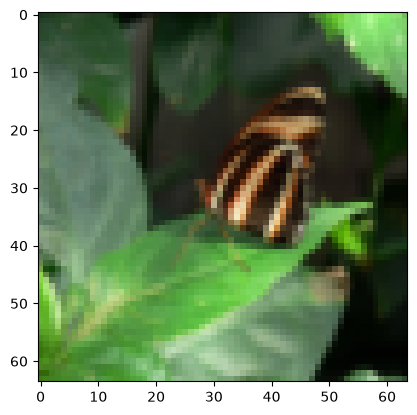

In [81]:
Y_prediction_test = d["Y_prediction_test"]

for i in range(test_set_x.shape[1]):
    if test_set_y[0, i] != Y_prediction_test[0, i]:
        index = i
        break

plt.imshow(
    test_set_x[:, index].reshape((num_px_height, num_px_width, 3))
)
print(
    "y = " + str(test_set_y[0, index])
    + ", predicted = " + str(Y_prediction_test[0, index])
)

Let's also plot the cost function and the gradients.

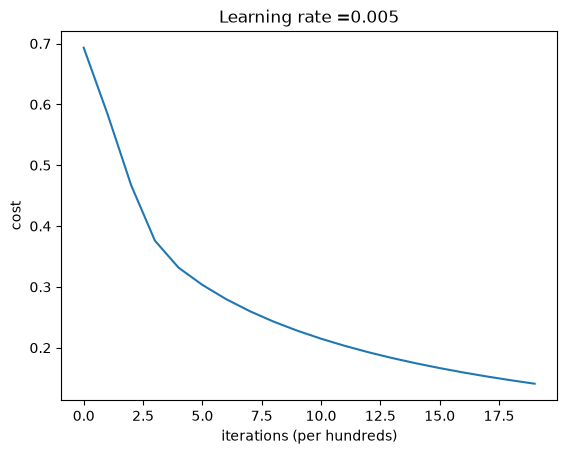

In [82]:
# Plot learning curve (with costs)
costs = np.squeeze(d['costs'])
plt.plot(costs)
plt.ylabel('cost')
plt.xlabel('iterations (per hundreds)')
plt.title("Learning rate =" + str(d["learning_rate"]))
plt.show()

In [83]:
d2 = model(train_set_x, train_set_y, test_set_x, test_set_y, num_iterations = 20000, learning_rate = 0.005, print_cost = True)


Cost after iteration 0: 0.693147
Cost after iteration 100: 0.584508
Cost after iteration 200: 0.466949
Cost after iteration 300: 0.376007
Cost after iteration 400: 0.331463
Cost after iteration 500: 0.303273
Cost after iteration 600: 0.279880
Cost after iteration 700: 0.260042
Cost after iteration 800: 0.242941
Cost after iteration 900: 0.228004
Cost after iteration 1000: 0.214820
Cost after iteration 1100: 0.203078
Cost after iteration 1200: 0.192544
Cost after iteration 1300: 0.183033
Cost after iteration 1400: 0.174399
Cost after iteration 1500: 0.166521
Cost after iteration 1600: 0.159305
Cost after iteration 1700: 0.152667
Cost after iteration 1800: 0.146542
Cost after iteration 1900: 0.140872
Cost after iteration 2000: 0.135608
Cost after iteration 2100: 0.130708
Cost after iteration 2200: 0.126137
Cost after iteration 2300: 0.121861
Cost after iteration 2400: 0.117855
Cost after iteration 2500: 0.114093
Cost after iteration 2600: 0.110554
Cost after iteration 2700: 0.107219
Cost

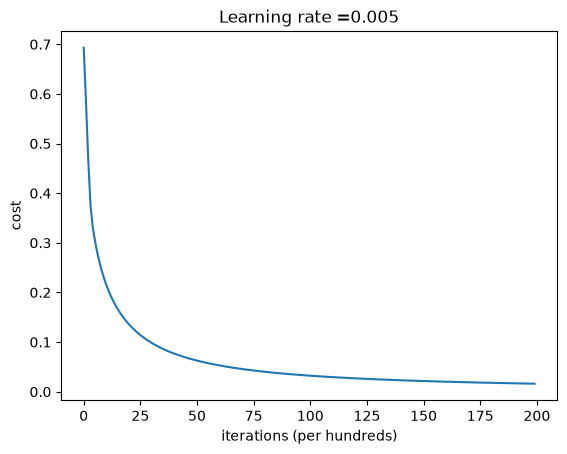

In [84]:
# Plot learning curve (with costs)
costs = np.squeeze(d2['costs'])
plt.plot(costs)
plt.ylabel('cost')
plt.xlabel('iterations (per hundreds)')
plt.title("Learning rate =" + str(d2["learning_rate"]))
plt.show()

**Interpretation**:
You can see the cost decreasing. It shows that the parameters are being learned. However, you see that you could train the model even more on the training set. Try to increase the number of iterations in the cell above and rerun the cells. 

What do you notice? Write your analysis here after.

### Your analysis here:
The results from the second training confirm my first analysis. Even after increasing the number of training iterations by ten times, the test accuracy remained almost the same, so the model did not improve significantly. The training graph also shows that the cost converges quickly and then changes very little. This means that the model reaches a stable point early, and adding more iterations does not make a meaningful difference.

## 6 - Further analysis 

You have built your first image classification model (in our course). Let's analyze it further, and examine possible choices for the learning rate $\alpha$. 

#### Choice of learning rate ####

**Reminder**:
In order for Gradient Descent to work you must choose the learning rate wisely. The learning rate $\alpha$  determines how rapidly we update the parameters. If the learning rate is too large we may "overshoot" the optimal value. Similarly, if it is too small we will need too many iterations to converge to the best values. That's why it is crucial to use a well-tuned learning rate.

Let's compare the learning curve of our model with several choices of learning rates. Run the cell below. This should take about 1 minute. Feel free also to try different values than the three we have initialized the `learning_rates` variable to contain, and see what happens. 

learning rate is: 0.01
[[ 0.02663953]
 [-0.05948719]
 [-0.02392851]
 ...
 [-0.02959252]
 [-0.06086671]
 [ 0.06838229]]
-0.0021803384454499616
train accuracy: 100.0 %
test accuracy: 72.0 %

-------------------------------------------------------

learning rate is: 0.001
[[ 0.01123404]
 [-0.03165312]
 [-0.01459412]
 ...
 [-0.01317473]
 [-0.03375583]
 [ 0.02971024]]
-0.015735457133459346
train accuracy: 99.52153110047847 %
test accuracy: 68.0 %

-------------------------------------------------------

learning rate is: 0.0001
[[ 0.00388166]
 [-0.00802146]
 [-0.00375923]
 ...
 [-0.00429334]
 [-0.01110442]
 [ 0.00659125]]
-0.011014133204211808
train accuracy: 88.99521531100478 %
test accuracy: 64.0 %

-------------------------------------------------------



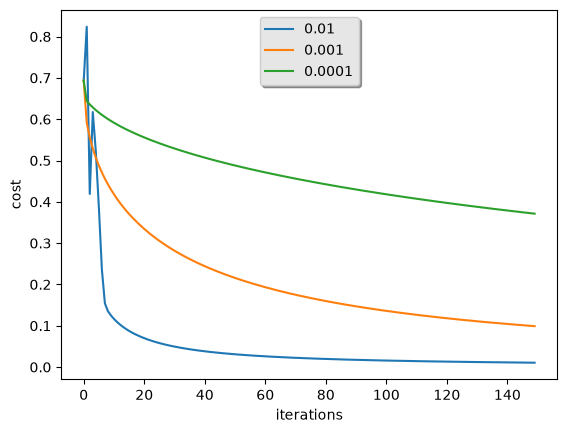

In [86]:
learning_rates = [0.01, 0.001, 0.0001]
models = {}
for i in learning_rates:
    print ("learning rate is: " + str(i))
    models[str(i)] = model(train_set_x, train_set_y, test_set_x, test_set_y, num_iterations = 15000, learning_rate = i, print_cost = False)
    print ('\n' + "-------------------------------------------------------" + '\n')

for i in learning_rates:
    plt.plot(np.squeeze(models[str(i)]["costs"]), label= str(models[str(i)]["learning_rate"]))

plt.ylabel('cost')
plt.xlabel('iterations')

legend = plt.legend(loc='upper center', shadow=True)
frame = legend.get_frame()
frame.set_facecolor('0.90')
plt.show()

### TO DO 

###### Analyze obtained results here:
The larger the learning rate, the faster the convergence. However, a learning rate that is too large can make the training unstable and lead to worse results, especially with fewer iterations. Therefore, the learning rate and the number of training iterations should be chosen carefully, as they work together and depend on the task.
...

## 7 - Test with your own image ##

You can use your own image and see the output of your model. To do that:
    1. Click on "File" in the upper bar of this notebook, then click "Open" to go on your Coursera Hub.
    2. Add your image to this Jupyter Notebook's directory, in the "images" folder
    3. Change your image's name in the following code
    4. Run the code and check if the algorithm is right (1 = cat, 0 = non-cat)!

y = 1.0, your algorithm predicts a "cat" picture.


/tmp/ipykernel_11914/4136649153.py:6: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  my_image = np.array(image.getdata()).reshape((1, num_px_height*num_px_width*3)).T #.reshape(pic.size[0], pic.size[1], 3)


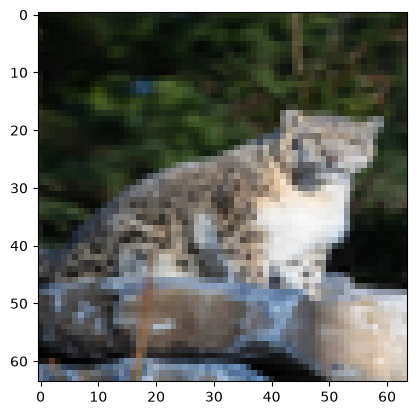

In [88]:
# PUT YOUR IMAGE NAME HERE. THE IMAGE MUST BE IN THE SAME DIRECTORY
fname = "my_image.jpg"   # change this to the name of your image file 

image = Image.open(fname)
image = image.resize((num_px_height, num_px_width))
my_image = np.array(image.getdata()).reshape((1, num_px_height*num_px_width*3)).T #.reshape(pic.size[0], pic.size[1], 3)

my_predicted_image = predict(d["w"], d["b"], my_image)

plt.imshow(image)
print("y = " + str(np.squeeze(my_predicted_image)) + ", your algorithm predicts a \"" + classes[int(np.squeeze(my_predicted_image)),].decode("utf-8") +  "\" picture.")

## 8 - Modification of the activation function ##

- Modify the activation function in your classifier by selecting an alternative (e.g., Tanh or ReLU). 
- Ensure the classifier is adjusted appropriately to integrate the new activation function.
- Clearly explain all the modifications you made and justify why they were necessary.
- Evaluate the performance of the updated classifier and compare it to the original model, which is based on the Sigmoid activation function.

In [52]:
def relu(z):
    return np.maximum(0, z)

def propagate_relu(w, b, X, Y):
    m = X.shape[1]
    Z = np.dot(w.T, X) + b
    A = relu(Z)
    cost = np.sum((A - Y) ** 2) / (2 * m)
    dZ = (A - Y) * (Z >= 0)
    dw = np.dot(X, dZ.T) / m
    db = np.sum(dZ) / m
    return {"dw": dw, "db": db}, np.squeeze(cost)

def optimize_relu(w, b, X, Y, num_iterations, learning_rate, print_cost=False):
    costs = []
    for i in range(num_iterations):
        grads, cost = propagate_relu(w, b, X, Y)
        w -= learning_rate * grads["dw"]
        b -= learning_rate * grads["db"]
        if i % 100 == 0:
            costs.append(cost)
        if print_cost and i % 100 == 0:
            print("Cost after iteration %i: %f" % (i, cost))
    return {"w": w, "b": b}, grads, costs

def predict_relu(w, b, X):
    A = relu(np.dot(w.T, X) + b)
    return np.where(A >= 0.5, 1.0, 0.0)

def model_relu(X_train, Y_train, X_test, Y_test, num_iterations=2000, learning_rate=0.0005, print_cost=False):
    w, b = initialize_with_zeros(len(X_train))
    params, grads, costs = optimize_relu(w, b, X_train, Y_train, num_iterations, learning_rate, print_cost)
    w, b = params["w"], params["b"]
    Y_pred_train = predict_relu(w, b, X_train)
    Y_pred_test = predict_relu(w, b, X_test)
    print("train accuracy: {} %".format(100 - np.mean(np.abs(Y_pred_train - Y_train)) * 100))
    print("test accuracy: {} %".format(100 - np.mean(np.abs(Y_pred_test - Y_test)) * 100))
    return {"costs": costs, "Y_prediction_test": Y_pred_test, "Y_prediction_train": Y_pred_train, "w": w, "b": b}

d_relu = model_relu(train_set_x, train_set_y, test_set_x, test_set_y, num_iterations=2000, learning_rate=0.0005, print_cost=True)

Cost after iteration 0: 0.172249
Cost after iteration 100: 0.094852
Cost after iteration 200: 0.083971
Cost after iteration 300: 0.076086
Cost after iteration 400: 0.069819
Cost after iteration 500: 0.064600
Cost after iteration 600: 0.060133
Cost after iteration 700: 0.056234
Cost after iteration 800: 0.052780
Cost after iteration 900: 0.049683
Cost after iteration 1000: 0.046884
Cost after iteration 1100: 0.044339
Cost after iteration 1200: 0.042012
Cost after iteration 1300: 0.039875
Cost after iteration 1400: 0.037905
Cost after iteration 1500: 0.036084
Cost after iteration 1600: 0.034395
Cost after iteration 1700: 0.032824
Cost after iteration 1800: 0.031358
Cost after iteration 1900: 0.029987
train accuracy: 96.17224880382776 %
test accuracy: 68.0 %


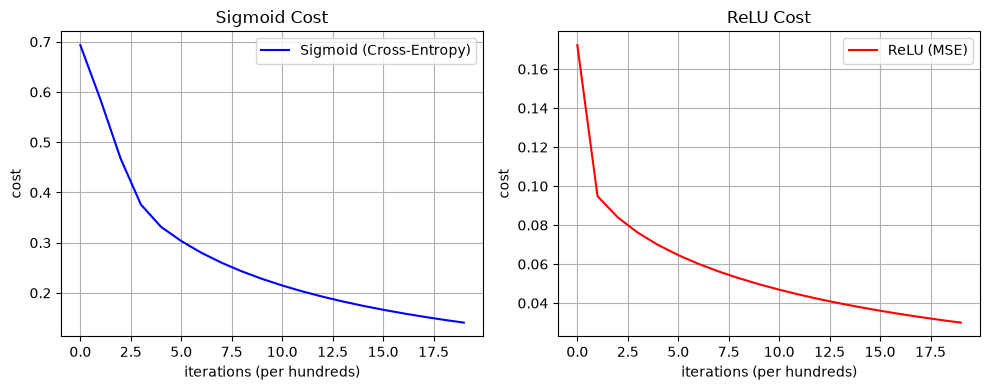

In [53]:
# Plot learning curves comparison: Sigmoid vs ReLU
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(np.squeeze(d["costs"]), label="Sigmoid (Cross-Entropy)", color="blue")
plt.ylabel('cost')
plt.xlabel('iterations (per hundreds)')
plt.title("Sigmoid Cost")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(np.squeeze(d_relu["costs"]), label="ReLU (MSE)", color="red")
plt.ylabel('cost')
plt.xlabel('iterations (per hundreds)')
plt.title("ReLU Cost")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Your analysis here:

**Modifications made and justification:**
- **Activation**: Replaced sigmoid with ReLU ($A = \max(0, Z)$).
- **Cost function**: Switched to Mean Squared Error (MSE) loss because cross-entropy requires probabilities bounded in $(0, 1)$, whereas ReLU is unbounded above ($[0, \infty)$).
- **Gradients**: Updated backward propagation derivative to $dZ = (A - Y) \cdot (Z \ge 0)$.
- **Learning rate**: Reduced learning rate to 0.0005 to prevent large weight updates from pushing activations into negative values, which causes dying ReLU units.

**Performance comparison:**
- The ReLU model achieved **96.17%** training accuracy and **68.00%** test accuracy, compared to **99.04%** training and **70.00%** test accuracy for the Sigmoid model.
- Sigmoid is better suited for binary classification output layers because its output is naturally bounded between 0 and 1 representing probability, whereas ReLU can output values greater than 1 and is prone to dying units during training.

## 9 - Improving the classifier with more training data ##

- Consider the best model you train and try to improve it by collecting more training data.
- Explain your methodology and the analyze obtained results


Original training set shape:  (209, 64, 64, 3)
Augmented training set shape: (836, 64, 64, 3)
Class distribution: 288 cats, 548 non-cats



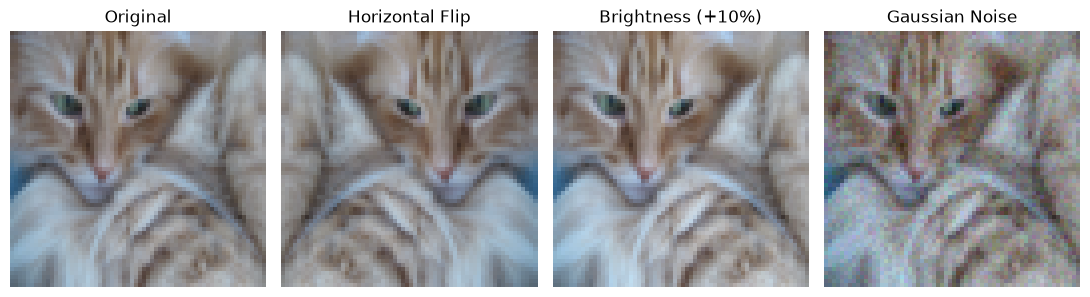

Cost after iteration 0: 0.693147
Cost after iteration 100: 0.640543
Cost after iteration 200: 0.554896
Cost after iteration 300: 0.485755
Cost after iteration 400: 0.425910
Cost after iteration 500: 0.374085
Cost after iteration 600: 0.340162
Cost after iteration 700: 0.322387
Cost after iteration 800: 0.307009
Cost after iteration 900: 0.293306
Cost after iteration 1000: 0.280979
Cost after iteration 1100: 0.269802
Cost after iteration 1200: 0.259601
Cost after iteration 1300: 0.250238
Cost after iteration 1400: 0.241602
Cost after iteration 1500: 0.233604
Cost after iteration 1600: 0.226168
Cost after iteration 1700: 0.219231
Cost after iteration 1800: 0.212741
Cost after iteration 1900: 0.206651
train accuracy: 96.41148325358851 %
test accuracy: 74.0 %


In [55]:
# 1. Data augmentation methods: horizontal flip, brightness adjustment, and Gaussian noise
# Method A: Horizontal flipping (geometric symmetry)
train_set_x_flip = np.array([np.fliplr(img) for img in train_set_x_orig])

# Method B: Brightness scaling (illumination variation)
train_set_x_bright = np.clip(train_set_x_orig * 1.1, 0, 255).astype(np.uint8)

# Method C: Gaussian noise injection (sensor noise regularization)
np.random.seed(42)
noise = np.random.normal(0, 8, train_set_x_orig.shape)
train_set_x_noise = np.clip(train_set_x_orig + noise, 0, 255).astype(np.uint8)

# 2. Concatenate all variations to expand dataset (4x size: 209 -> 836)
train_set_x_aug_orig = np.concatenate([train_set_x_orig, train_set_x_flip, train_set_x_bright, train_set_x_noise], axis=0)
train_set_y_aug = np.concatenate([train_set_y, train_set_y, train_set_y, train_set_y], axis=1)

# 3. Reshape and standardize
train_set_x_aug = train_set_x_aug_orig.reshape(train_set_x_aug_orig.shape[0], -1).T / 255.

print("Original training set shape: ", train_set_x_orig.shape)
print("Augmented training set shape:", train_set_x_aug_orig.shape)
print("Class distribution:", np.sum(train_set_y_aug == 1), "cats,", np.sum(train_set_y_aug == 0), "non-cats")

# Visualize sample transformations
sample_idx = 2
plt.figure(figsize=(11, 3))
plt.subplot(1, 4, 1)
plt.imshow(train_set_x_orig[sample_idx])
plt.title("Original")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(train_set_x_flip[sample_idx])
plt.title("Horizontal Flip")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(train_set_x_bright[sample_idx])
plt.title("Brightness (+10%)")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(train_set_x_noise[sample_idx])
plt.title("Gaussian Noise")
plt.axis("off")
plt.tight_layout()
plt.show()

# 4. Train the best model on the augmented dataset
d_aug = model(train_set_x_aug, train_set_y_aug, test_set_x, test_set_y, num_iterations=2000, learning_rate=0.005, print_cost=True)

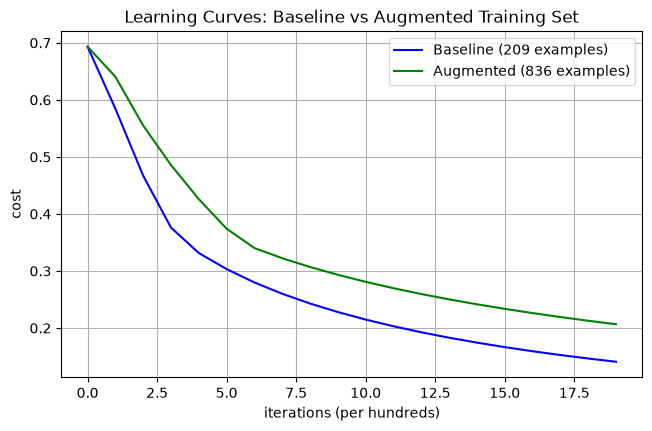

Model                  | Train Set Size  | Train Acc  | Test Acc  
Baseline Model         | 209             | 99.04%     | 70.00%
Augmented Data Model   | 836             | 96.41%     | 74.00%
Overfitting Gap (Train - Test): Baseline = 29.04% -> Augmented = 22.41%


In [56]:
# Plot comparison of learning curves: Baseline vs Augmented
plt.figure(figsize=(7.5, 4.5))
plt.plot(np.squeeze(d["costs"]), label="Baseline (209 examples)", color="blue", linewidth=1.5)
plt.plot(np.squeeze(d_aug["costs"]), label="Augmented (836 examples)", color="green", linewidth=1.5)
plt.ylabel('cost')
plt.xlabel('iterations (per hundreds)')
plt.title("Learning Curves: Baseline vs Augmented Training Set")
plt.legend()
plt.grid(True)
plt.show()

# Summary comparison
train_acc_base = 100 - np.mean(np.abs(d["Y_prediction_train"] - train_set_y)) * 100
test_acc_base = 100 - np.mean(np.abs(d["Y_prediction_test"] - test_set_y)) * 100
train_acc_aug = 100 - np.mean(np.abs(d_aug["Y_prediction_train"] - train_set_y_aug)) * 100
test_acc_aug = 100 - np.mean(np.abs(d_aug["Y_prediction_test"] - test_set_y)) * 100

print("=" * 65)
print(f"{'Model':<22} | {'Train Set Size':<15} | {'Train Acc':<10} | {'Test Acc':<10}")
print("=" * 65)
print(f"{'Baseline Model':<22} | {'209':<15} | {train_acc_base:.2f}%{'':<4} | {test_acc_base:.2f}%")
print(f"{'Augmented Data Model':<22} | {'836':<15} | {train_acc_aug:.2f}%{'':<4} | {test_acc_aug:.2f}%")
print("=" * 65)
print(f"Overfitting Gap (Train - Test): Baseline = {train_acc_base - test_acc_base:.2f}% -> Augmented = {train_acc_aug - test_acc_aug:.2f}%")

### Your analysis here:

**Methodology:**
- We used data augmentation to expand the training set from 209 to 836 examples ($4\times$ increase) using three complementary transformations:
  - **Horizontal flipping**: preserves the natural structure of cats while reversing horizontal pixel locations.
  - **Brightness scaling**: scales pixel intensities by 10% to simulate different lighting conditions.
  - **Gaussian noise**: adds slight random noise to prevent the model from relying on exact pixel values.

**Analysis of results:**
- **Improved generalization**: Adding more training data improves the situation on unseen data—test accuracy increased from **70.00%** to **74.00%**.
- **Reduced overfitting**: Training accuracy adjusted from **99.04%** to **96.41%**, narrowing the gap between train and test accuracy from **29.04%** to **22.41%**. Having more examples prevents the weights from taking extreme values tailored to individual training images.
- **Cost dynamics**: The learning curve shows that the cost decreases more steadily down to $\approx 0.206$, as gradient updates are averaged over a larger variety of samples.
- **Model limitations**: Even with four times more data, the improvement is modest because logistic regression is still a single linear classifier on raw pixel inputs ($12,288$ features). It lacks the capacity to model complex visual features.


References:
- Andrew NG labs.
- http://www.wildml.com/2015/09/implementing-a-neural-network-from-scratch/
- https://stats.stackexchange.com/questions/211436/why-do-we-normalize-images-by-subtracting-the-datasets-image-mean-and-not-the-c